In [54]:
import inspect 
import json 
import re 
import time 
from pathlib import Path 
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import QuantLib as ql 
import torch 
from scipy.stats import norm 
from torch import nn

In [55]:
ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
OUT = ROOT / 'experiment_computational_effiency_result' / 'comp_eff_ex'
OUT.mkdir(parents=True, exist_ok=True)
FEATURES = ['S0', 'K', 'T', 'r', 'v0', 'kappa', 'theta', 'sigma', 'rho']
WORKLOADS = [1,10,100,500,1000,5000]
BATCHES = [32, 512, 2048]
QL_REPEATS, ML_REPEATS = 3, 7 
torch.set_num_threads(1)

In [56]:
mc = ROOT / 'experiment_model_comparison_results'/'n12000'
trials = pd.read_csv(mc/'model_comparison_trials.csv')
row = trials[trials.model == 'Hybrid BS-MLP'].sort_values('validation_mae').iloc[0]
seed = int(row.model_seed)
load_options = {'map_location':'cpu'}
if 'weights_only' in inspect.signature(torch.load).parameters:
    load_options['weights_only'] = False 
checkpoint = torch.load(str(mc/'modelS'/f'model_Hybrid_seed{seed}.pt'), **load_options)
assert list(checkpoint['features']) == FEATURES and checkpoint['target'] == 'residual'

class MLP(nn.Module): 
    def __init__(self, hidden_units):
        super().__init__()
        layers = []
        width = len(FEATURES)
        for hidden_width in hidden_units: 
            layers.extend([
                nn.Linear(width, hidden_width), 
                nn.ReLU()])
            width = hidden_width
        layers.append(nn.Linear(width, 1))
        self.net = nn.Sequential(*layers)
    def forward(self,x):
        return self.net(x)
    

model = MLP(checkpoint['hidden_units']).cpu().eval()
model.load_state_dict(checkpoint['model_state_dict'])
mean, std = np.asarray(checkpoint['x_mean']), np.asarray(checkpoint['x_scale'])
ym, ys = float(checkpoint['y_mean'][0]), float(checkpoint['y_scale'][0])

def ml_prices(x,batch=512):
    x = np.asarray(x, dtype=np.float64)
    data = torch.from_numpy(((x - mean) / std).astype(np.float32))
    with torch.no_grad():
        resid = np.concatenate([model(part).numpy().ravel()
                    for part in data.split(batch)]) * ys + ym 
    S, K, T, r, v0, kappa, theta = x[:, :7].T
    a = kappa * T 
    w = np.divide(-np.expm1(-a), a, out=np.ones_like(a), where=a != 0)
    v = theta + (v0 - theta) * w
    vol_t = np.sqrt(v * T)
    d1 = (np.log(S / K) + (r + v/2) * T)/vol_t
    bs = S * norm.cdf(d1) - K * np.exp(-r*T) * norm.cdf(d1 - vol_t)
    return bs + resid

In [57]:
start_date, day_count = ql.Date(2, ql.January, 2026), ql.Actual365Fixed()
ql.Settings.instance().evaluationDate = start_date 

def ql_price(x):
    S, K, T, r, v0, kappa, theta, sigma, rho = map(float, x)
    risk = ql.YieldTermStructureHandle(ql.FlatForward(start_date, r, day_count))
    div = ql.YieldTermStructureHandle(ql.FlatForward(start_date, 0.0, day_count))
    proc = ql.HestonProcess(risk, div, ql.QuoteHandle(ql.SimpleQuote(S)), v0, kappa, theta, sigma, rho)
    opt = ql.VanillaOption(ql.PlainVanillaPayoff(ql.Option.Call, K), ql.EuropeanExercise(start_date + max(1, round(T * 365))))
    opt.setPricingEngine(ql.AnalyticHestonEngine(ql.HestonModel(proc), 128))
    return float(opt.NPV())

def ql_prices(x): 
    return np.fromiter((ql_price(v) for v in x), float, count=len(x))

In [58]:
test = pd.read_csv(ROOT / 'experiment_baseline'/'test.csv')
extension = pd.read_csv(
    ROOT / 'experiment_training_size_results'/'data'/'extension_11000.csv'
)
test_x = test[FEATURES].to_numpy(float)
x = np.vstack([
    test_x, 
    extension[FEATURES].to_numpy(float)[:max(WORKLOADS)-len(test_x)]
])

assert len(x) == max(WORKLOADS)

pred = ml_prices(test_x)
saved = pd.read_csv(
    mc / 'predictions' /
    f'test_prediction_Hybrid_BS-MLP_seed{seed}.csv'
)['predicted_price'].to_numpy()

assert np.max(
    np.abs(pred - saved)) < 2e-6, 'Saved model predictions do not match'

check = np.array([0,100,250,499])

assert np.max(
    np.abs(ql_prices(test_x[check]) - test.price.to_numpy()[check])
) < 5e-6, 'QuantLib prices differ from earlier reference'
errors = pred - test.price.to_numpy()
print(f'Best Hybrid seed: {seed} | ' ,
      f'Test MAE: {np.abs(errors).mean():.6g} | '
      f'| Test RMSE: {np.sqrt(np.mean(errors**2)):.6g}')

Best Hybrid seed: 44 |  Test MAE: 8.531e-05 | | Test RMSE: 0.000250807


In [59]:
def median_time(fn, repeats): 
    fn()
    times = []
    for _ in range(repeats): 
        t = time.perf_counter()
        result = fn()
        times.append(time.perf_counter() - t)
    assert np.isfinite(result).all()
    return float(np.median(times))

records=[]
for n in WORKLOADS: 
    block = x[:n]
    qt = median_time(lambda: ql_prices(block), QL_REPEATS)
    for batch in sorted({min(n, b) for b in BATCHES}):
        mt = median_time(
            lambda batch=batch: ml_prices(block, batch), 
            ML_REPEATS
        )
        records.append({
            'n':n, 
            'batch':batch, 
            'quantlib_s': qt, 
            'hybrid_s': mt, 
            'speedup': qt / mt
        })
    print(f'Completed {n:,} contracts')

results = pd.DataFrame(records)
results.to_csv(OUT / 'timings.csv', index=False)
scaling = results[
    results.batch == results.n.clip(upper=512)
].copy()

scaling.to_csv(OUT/'scaling.csv', index=False)

print('\n512-batch scaling results:')
print(scaling.round(5).to_string(index=False))

Completed 1 contracts
Completed 10 contracts
Completed 100 contracts
Completed 500 contracts
Completed 1,000 contracts
Completed 5,000 contracts

512-batch scaling results:
   n  batch  quantlib_s  hybrid_s   speedup
   1      1     0.00143   0.00093   1.54074
  10     10     0.01582   0.00040  39.06699
 100    100     0.14767   0.00051 289.42130
 500    500     0.74688   0.00143 523.36089
1000    512     1.48241   0.00225 659.88290
5000    512     7.39682   0.00879 841.89436


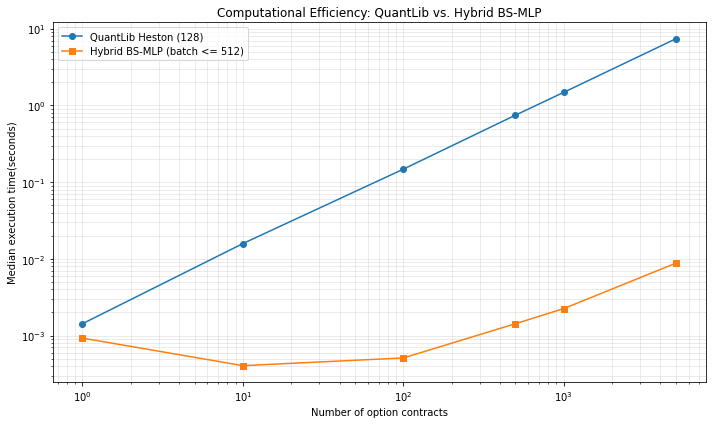

In [60]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    scaling['n'].to_numpy(), 
    scaling['quantlib_s'].to_numpy(), 
    'o-', 
    label='QuantLib Heston (128)'
)
ax.plot(
    scaling['n'].to_numpy(), 
    scaling['hybrid_s'].to_numpy(), 
    's-', 
    label='Hybrid BS-MLP (batch <= 512)'
)
ax.set(
    xscale='log', 
    yscale='log', 
    xlabel='Number of option contracts', 
    ylabel='Median execution time(seconds)', 
    title='Computational Efficiency: QuantLib vs. Hybrid BS-MLP'
)
ax.legend()
ax.grid(True, which='both', alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / 'runtime.png', dpi=220)
plt.show()


fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    scaling['n'].to_numpy(), 
    scaling['speedup'].to_numpy(), 
    'o-'
)
ax.axhline(1, linestyle='--', color='grey')
ax.set(
    xscale='log', 
    xlabel='Number of option contracts', 
    ylabel='QuantLib time / ML time', 
    title='Hybrid BS-MLP Speedup Relative to QuantLib'
)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / 'speedup.png', dpi=220)
plt.close(fig)

batch_data = results[
    results.n == max(WORKLOADS)
].sort_values('batch')
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(
    batch_data['batch'].to_numpy(),
    (
        1000 * batch_data['hybrid_s']/batch_data['n']
    ).to_numpy(),
    'o-'
)
ax.set(
    xscale = 'log', 
    xlabel = 'ML Batch Size',
    ylabel='Milliseconds per option',
    title=f'Batch-size sensitivity'
)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'batch_size_scaling.png', dpi=220)
plt.close(fig)

In [61]:
notebook = json.loads(
    (ROOT / 'exp_model_comp.ipynb').read_text(encoding='utf-8')
)
output_text = ''.join(
    ''.join(o.get('text',[])) 
    for cell in notebook['cells'] 
    for o in cell.get('outputs',[])
)
match = re.search(
    rf'Hybrid seed={seed}:\s*best epoch=\d+, \s*training=([\d.]+)s', 
    output_text
)

if match is None: 
    raise ValueError("Training time not found in notebook outputs")

training_s = float(match.group(1)) 
last = scaling.iloc[-1]
ql_per = last.quantlib_s / last.n
ml_per = last.hybrid_s / last.n 
label_s = (12000 + 200) * ql_per 
break_even = (
    (training_s + label_s)/(ql_per - ml_per) 
    if ql_per > ml_per 
    else None
)
summary = {
    'seed':seed,
    'test_mae': float(np.abs(errors).mean()),
    'test_rmse': float(np.sqrt(np.mean(errors ** 2))),
    'historical_training_seconds': training_s, 
    'estimated_label_generation_seconds': label_s, 
    'estimated_break_even_contracts': break_even,
    'NOTE': 'Break-even is estimated using historical training time, '
         'current marginal timing and linear scaling. Not directly measured'
}
(OUT / 'break_even_estimate.json').write_text(
    json.dumps(summary, indent=2)
)
print(f'Training time: {training_s:.2f} seconds')
print(f'Estimated label-generation time: {label_s:.2f} seconds')
print(
    f'Exploratory break even: {break_even:,.0f} prices'
    if break_even is not None 
    else 'No break-even: ML is faster'
)
print('Results saved to:', OUT)
         

Training time: 193.07 seconds
Estimated label-generation time: 18.05 seconds
Exploratory break even: 142,878 prices
Results saved to: /Users/john.madhu_/Desktop/MSC_thesis/src/heston/experiment_computational_effiency_result/comp_eff_ex


In [62]:
block = x[:5000]
repeat_results = []

for run in range(1, 4):
    qt = median_time(
        lambda: ql_prices(block), QL_REPEATS
    )
    mt = median_time(
        lambda: ml_prices(block, 512), ML_REPEATS
    )
    repeat_results.append({
        'Run': run,
        'QuantLib (s)': qt,
        'Hybrid MLP (s)': mt,
        'Speedup': qt / mt
    })
    print(f'Run {run} completed')

repeat_df = pd.DataFrame(repeat_results)

print(repeat_df.round(5).to_string(index=False))

repeat_df.to_csv(
    OUT / 'timing_consistency.csv',
    index=False
)

Run 1 completed
Run 2 completed
Run 3 completed
 Run  QuantLib (s)  Hybrid MLP (s)   Speedup
   1       7.47281         0.00926 806.78188
   2       7.37368         0.00918 802.80713
   3       7.64461         0.00957 798.48490


In [63]:
for col in ['QuantLib (s)', 'Hybrid MLP (s)']: 
    values = repeat_df[col]
    print(f'\n{col}')
    print(f'Mean: {values.mean():.6f} s')
    print(f'Standard deviation: {values.std():.6f} s')
    print(f'CV: {100 * values.std() / values.mean():.2f}%')


QuantLib (s)
Mean: 7.497035 s
Standard deviation: 0.137081 s
CV: 1.83%

Hybrid MLP (s)
Mean: 0.009340 s
Standard deviation: 0.000206 s
CV: 2.20%
